# Will This Visitor Buy? Real-Time Purchase Intent
**NextGen Institute · Machine Learning · Final Project**

## 1. Problem framing
- **Who has the problem:** an online shop. Most visitors leave without buying, and giving a discount to *everyone* wastes margin.
- **Decision the model supports:** during a browsing session, decide whether to do nothing, show a coupon, or open a chat assistant.
- **Target:** `Revenue` (True = the session ended with a purchase).
- **Metrics:** the classes are imbalanced (~15% buyers), so accuracy is misleading. We use **ROC-AUC** and **PR-AUC** to compare models, and **recall / precision / F1** at a business-chosen threshold.

**Dataset:** Online Shoppers Purchasing Intention (UCI) — https://archive.ics.uci.edu/dataset/468

In [17]:
import warnings; warnings.filterwarnings("ignore")
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Data understanding

In [18]:
def load_data():
    # 1) local file (e.g. uploaded to Colab)
    if os.path.exists("online_shoppers_intention.csv"):
        return pd.read_csv("online_shoppers_intention.csv")
    # 2) UCI repository package (pip install ucimlrepo)
    try:
        from ucimlrepo import fetch_ucirepo
        d = fetch_ucirepo(id=468)
        return pd.concat([d.data.features, d.data.targets], axis=1)
    except Exception as e:
        print("ucimlrepo failed:", e)
    # 3) direct download
    import io, zipfile, urllib.request
    url = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    name = [n for n in z.namelist() if n.endswith(".csv")][0]
    return pd.read_csv(z.open(name))

df = load_data()
print(df.shape)
df.head()

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [19]:
df.info()
print("\nMissing values per column:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nClass balance:\n", df["Revenue"].value_counts(normalize=True).round(3))
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


**Column dictionary (short):**
`Administrative / Informational / ProductRelated` = number of pages visited of each type, with `_Duration` = seconds spent.
`BounceRates`, `ExitRates` = Google Analytics rates for the pages visited. `PageValues` = average value of pages seen before a purchase.
`SpecialDay` = closeness to a special day (e.g. Valentine's). `Month`, `Weekend`, `VisitorType`, plus technical IDs
`OperatingSystems`, `Browser`, `Region`, `TrafficType` (these are codes, so we treat them as categories, not numbers).

In [20]:
# Light cleaning (done before the split because it does not learn anything from the data)
df = df.drop_duplicates().reset_index(drop=True)
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
for c in ["OperatingSystems", "Browser", "Region", "TrafficType"]:
    df[c] = df[c].astype(str)
print(df.shape)

(12205, 18)


## 3. Exploratory data analysis

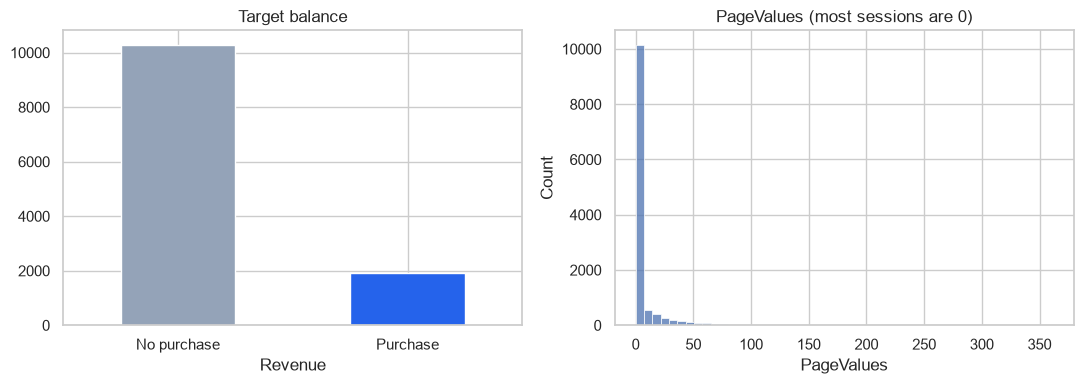

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df["Revenue"].value_counts().rename({0: "No purchase", 1: "Purchase"}).plot.bar(ax=ax[0], color=["#94a3b8", "#2563eb"])
ax[0].set_title("Target balance"); ax[0].tick_params(axis="x", rotation=0)
sns.histplot(df["PageValues"], bins=50, ax=ax[1]); ax[1].set_title("PageValues (most sessions are 0)")
plt.tight_layout(); plt.show()

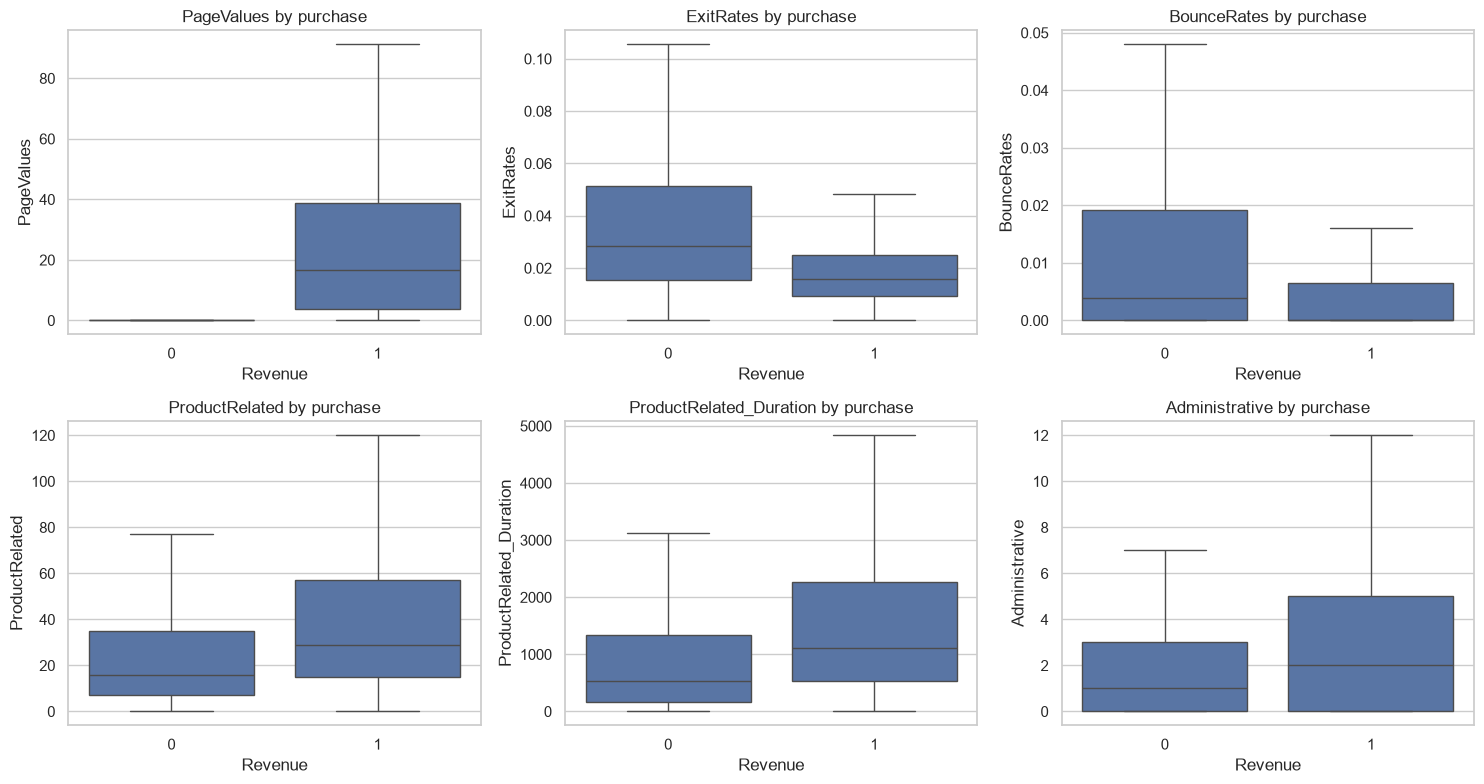

In [22]:
num_cols = ["Administrative","Administrative_Duration","Informational","Informational_Duration",
            "ProductRelated","ProductRelated_Duration","BounceRates","ExitRates","PageValues","SpecialDay"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(axes.ravel(), ["PageValues","ExitRates","BounceRates","ProductRelated","ProductRelated_Duration","Administrative"]):
    sns.boxplot(data=df, x="Revenue", y=c, ax=a, showfliers=False)
    a.set_title(f"{c} by purchase")
plt.tight_layout(); plt.show()

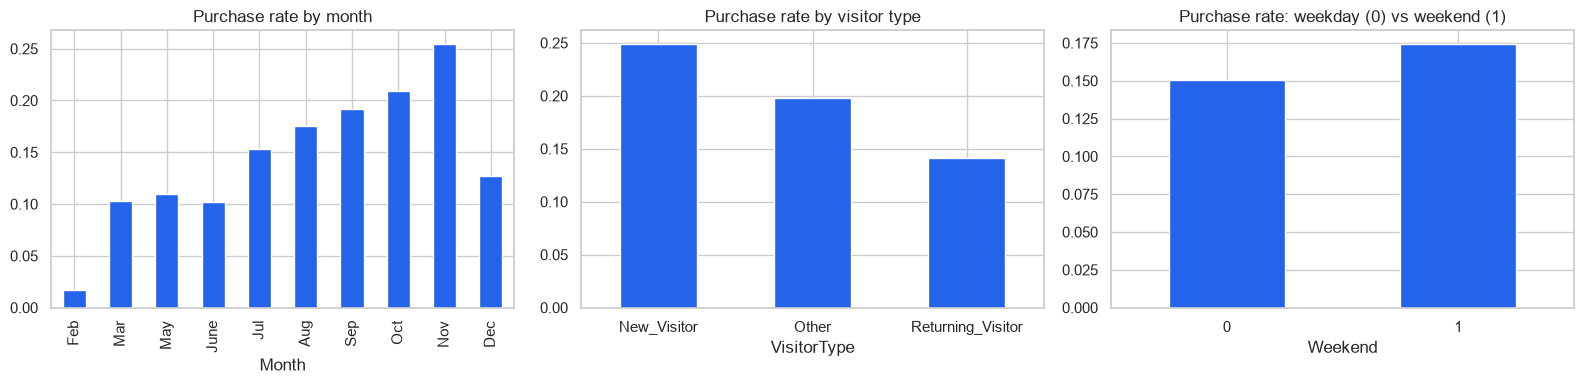

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
order = ["Feb","Mar","May","June","Jul","Aug","Sep","Oct","Nov","Dec"]
order = [m for m in order if m in df["Month"].unique()]
df.groupby("Month")["Revenue"].mean().reindex(order).plot.bar(ax=axes[0], color="#2563eb")
axes[0].set_title("Purchase rate by month")
df.groupby("VisitorType")["Revenue"].mean().plot.bar(ax=axes[1], color="#2563eb")
axes[1].set_title("Purchase rate by visitor type"); axes[1].tick_params(axis="x", rotation=0)
df.groupby("Weekend")["Revenue"].mean().plot.bar(ax=axes[2], color="#2563eb")
axes[2].set_title("Purchase rate: weekday (0) vs weekend (1)"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

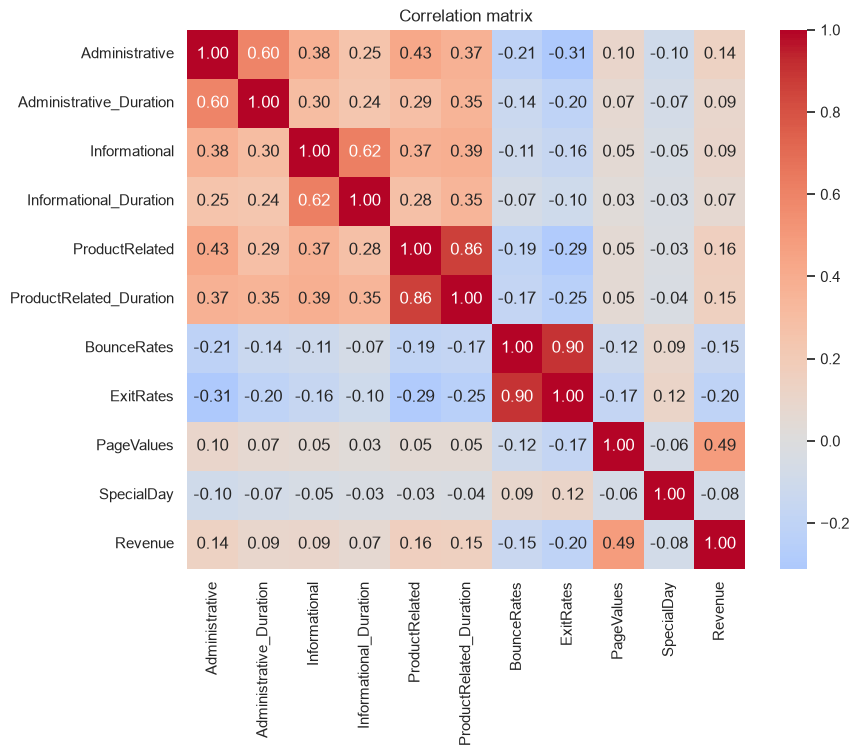

In [24]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols + ["Revenue"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

### Insights / hypotheses
*(Check each one against your charts above and edit the wording with the real numbers you see.)*
1. **`PageValues` is the strongest signal** — sessions that bought show much higher page values than sessions that did not.
2. **High `ExitRates` / `BounceRates` go with no purchase.** `BounceRates` and `ExitRates` are strongly correlated with each other (redundant information).
3. **Purchase rate changes with the calendar** — look at which months stand out (e.g. November) and compare returning vs new visitors.
4. **The classes are imbalanced**, so accuracy would be misleading and we need recall/precision/PR-AUC.

## 4. Train/test split and preprocessing pipeline
We split **first** (stratified), and every transformation lives inside a scikit-learn `Pipeline`, so nothing is learned from the test set (no leakage).

In [25]:
X = df.drop(columns="Revenue"); y = df["Revenue"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, "| train buyers: %.3f  test buyers: %.3f" % (y_train.mean(), y_test.mean()))

cat_cols = ["Month","VisitorType","OperatingSystems","Browser","Region","TrafficType"]
num_cols = [c for c in X.columns if c not in cat_cols]   # includes Weekend (0/1)

# Feature engineering lives in features.py so the saved pipeline can be loaded by the web app
FEATURES_PY = '''import numpy as np

def add_features(d):
    d = d.copy()
    d["TotalPages"] = d["Administrative"] + d["Informational"] + d["ProductRelated"]
    d["TotalDuration"] = d["Administrative_Duration"] + d["Informational_Duration"] + d["ProductRelated_Duration"]
    d["AvgSecPerPage"] = d["TotalDuration"] / d["TotalPages"].replace(0, np.nan)
    d["HasPageValue"] = (d["PageValues"] > 0).astype(int)
    return d
'''
open("features.py", "w").write(FEATURES_PY)
from features import add_features
from sklearn.preprocessing import FunctionTransformer
engineer = FunctionTransformer(add_features)
num_all = num_cols + ["TotalPages","TotalDuration","AvgSecPerPage","HasPageValue"]

def make_preprocessor(scale=True):
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_all),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)])

def make_pipe(model, scale=True):
    return Pipeline([("fe", engineer), ("prep", make_preprocessor(scale)), ("model", model)])

(9764, 17) (2441, 17) | train buyers: 0.156  test buyers: 0.156


## 5. Modeling: baseline + three algorithms

In [26]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
models = {
    "Baseline (majority)": make_pipe(DummyClassifier(strategy="most_frequent")),
    "Logistic Regression": make_pipe(LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": make_pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                                     n_jobs=-1, random_state=RANDOM_STATE), scale=False),
    "Gradient Boosting": make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
}
rows = []
for name, pipe in models.items():
    proba = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    rows.append({"model": name, "CV ROC-AUC": roc_auc_score(y_train, proba),
                 "CV PR-AUC": average_precision_score(y_train, proba)})
cv_results = pd.DataFrame(rows).set_index("model").round(4)
cv_results

,CV ROC-AUC,CV PR-AUC
model,,
Baseline (majority),0.5000,0.1563
Logistic Regression,0.9159,0.6689
Random Forest,0.9274,0.7448
Gradient Boosting,0.9289,0.7381


## 6. Hyperparameter tuning (cross-validation on the training set only)

In [27]:
grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "Random Forest": {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [1, 5, 10]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.05, 0.1],
                          "model__max_depth": [2, 3]},
}
best = {}
for name, grid in grids.items():
    gs = GridSearchCV(models[name], grid, scoring="average_precision", cv=cv, n_jobs=-1)
    gs.fit(X_train, y_train)
    best[name] = gs.best_estimator_
    print(f"{name:22s} best CV PR-AUC = {gs.best_score_:.4f}  params = {gs.best_params_}")

Logistic Regression    best CV PR-AUC = 0.6782  params = {'model__C': 0.01}
Random Forest          best CV PR-AUC = 0.7463  params = {'model__max_depth': None, 'model__min_samples_leaf': 5}
Gradient Boosting      best CV PR-AUC = 0.7468  params = {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 100}


## 7. Evaluation on the untouched test set
First we pick a **decision threshold** using out-of-fold predictions on the *training* data only (maximizing F1), then apply it once to the test set.

In [28]:
def pick_threshold(pipe):
    p = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    return float(thr[np.argmax(f1)])

dummy = models["Baseline (majority)"].fit(X_train, y_train)
results, thresholds = [], {}
p = dummy.predict_proba(X_test)[:, 1]; pred = dummy.predict(X_test)
results.append({"model": "Baseline (majority)", "threshold": 0.5, "accuracy": accuracy_score(y_test, pred),
                "precision": 0.0, "recall": 0.0, "F1": 0.0,
                "ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p)})
for name, pipe in best.items():
    pipe.fit(X_train, y_train)
    thr = pick_threshold(pipe); thresholds[name] = thr
    p = pipe.predict_proba(X_test)[:, 1]; pred = (p >= thr).astype(int)
    results.append({"model": name, "threshold": thr, "accuracy": accuracy_score(y_test, pred),
                    "precision": precision_score(y_test, pred), "recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p),
                    "PR-AUC": average_precision_score(y_test, p)})
results = pd.DataFrame(results).set_index("model").round(4)
results

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
model,,,,,,,
Baseline (majority),0.5000,0.8435,0.0000,0.0000,0.0000,0.5000,0.1565
Logistic Regression,0.6554,0.8832,0.5945,0.7984,0.6816,0.9266,0.6960
Random Forest,0.5929,0.8947,0.6485,0.7147,0.6800,0.9334,0.7450
Gradient Boosting,0.3479,0.8992,0.6619,0.7277,0.6933,0.9372,0.7477


Final model: Gradient Boosting | threshold: 0.348


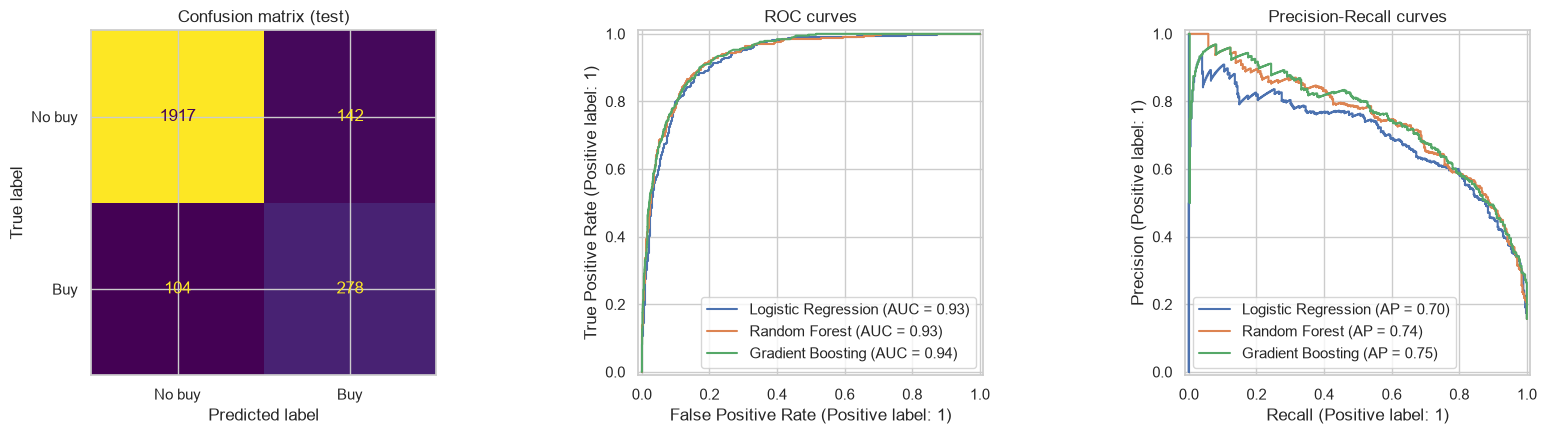

In [29]:
best_name = results.drop("Baseline (majority)")["PR-AUC"].idxmax()
final = best[best_name]; thr = thresholds[best_name]
print("Final model:", best_name, "| threshold:", round(thr, 3))

p_test = final.predict_proba(X_test)[:, 1]; pred = (p_test >= thr).astype(int)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["No buy", "Buy"]).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (test)")
for name, pipe in best.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, ax=ax[1], name=name)
    PrecisionRecallDisplay.from_estimator(pipe, X_test, y_test, ax=ax[2], name=name)
ax[1].set_title("ROC curves"); ax[2].set_title("Precision-Recall curves")
plt.tight_layout(); plt.show()

### Error analysis and feature importance

Missed buyers (false negatives): 104 | False alarms (false positives): 142

Median PageValues  -> missed buyers: 0.00 | caught buyers: 27.86
Missed buyers by visitor type:
 VisitorType
Returning_Visitor    0.78
New_Visitor          0.22
Name: proportion, dtype: float64


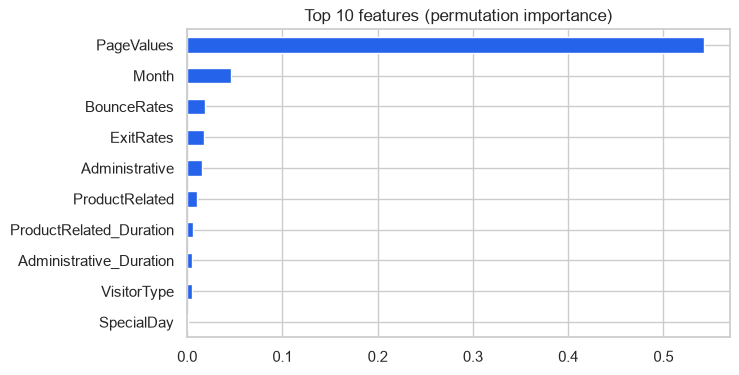

In [30]:
err = X_test.copy(); err["y"] = y_test.values; err["p"] = p_test; err["pred"] = pred
fn = err[(err.y == 1) & (err.pred == 0)]; fp = err[(err.y == 0) & (err.pred == 1)]
print(f"Missed buyers (false negatives): {len(fn)} | False alarms (false positives): {len(fp)}")
print("\nMedian PageValues  -> missed buyers: %.2f | caught buyers: %.2f" %
      (fn.PageValues.median(), err[(err.y==1)&(err.pred==1)].PageValues.median()))
print("Missed buyers by visitor type:\n", fn.VisitorType.value_counts(normalize=True).round(2))

pi = permutation_importance(final, X_test, y_test, scoring="average_precision", n_repeats=10,
                            random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values().tail(10)
imp.plot.barh(figsize=(7, 4), color="#2563eb"); plt.title("Top 10 features (permutation importance)"); plt.show()

### Stretch: coupon campaign simulation

In [31]:
# Policy: show a coupon to the sessions with the HIGHEST predicted probability among those NOT already certain to buy.
# Simple view: how concentrated are buyers in the top-scored sessions? (lift)
sim = pd.DataFrame({"y": y_test.values, "p": p_test}).sort_values("p", ascending=False).reset_index(drop=True)
for frac in [0.05, 0.10, 0.20, 0.30]:
    top = sim.head(int(len(sim) * frac))
    print(f"Top {int(frac*100):>2}% scored sessions -> contain {top.y.sum() / sim.y.sum():.0%} of all buyers "
          f"(lift {top.y.mean() / sim.y.mean():.1f}x)")

Top  5% scored sessions -> contain 28% of all buyers (lift 5.7x)
Top 10% scored sessions -> contain 51% of all buyers (lift 5.1x)
Top 20% scored sessions -> contain 78% of all buyers (lift 3.9x)
Top 30% scored sessions -> contain 91% of all buyers (lift 3.0x)


## 8. Business insight and limitations
The best model is Gradient Boosting with ROC-AUC 0.937, PR-AUC 0.748, recall 72.8% and precision 66.2% at threshold 0.35, compared with a baseline that never predicts a purchase (PR-AUC 0.157).
In plain words: out of every 100 sessions that end in a purchase, the model catches about 73, and about 2 of every 3 sessions it flags really do buy.
- The best model is **[model name]** with ROC-AUC **[X]**, PR-AUC **[X]**, recall **[X]** and precision **[X]** at threshold **[X]**, compared with a baseline that never predicts a purchase.
- **How to use it:** high probability → do nothing (they will buy anyway, no discount needed). Medium probability → show a coupon. Low probability but high exit rate → open the chat assistant.
- **Next step:** A/B test the coupon policy on live traffic to measure real uplift and coupon ROI.
- **Limitations:** (1) one site, 12K sessions from a single year; (2) `PageValues` is only known late in a session, so early-session predictions will be weaker; (3) the data shows correlation, not whether a coupon *causes* a purchase; (4) the threshold depends on the cost of a coupon vs the value of a sale.

## 9. Save the pipeline for the web app

In [32]:
# Retrain the final pipeline on ALL data would also be valid; we keep the train-only model so test scores stay honest.
defaults = {"num": X_train[num_cols].median().to_dict(),
            "cat": {c: X_train[c].mode()[0] for c in ["OperatingSystems","Browser","Region","TrafficType"]},
            "months": sorted(X_train["Month"].unique().tolist()),
            "visitor_types": sorted(X_train["VisitorType"].unique().tolist())}
joblib.dump({"pipeline": final, "threshold": thr, "model_name": best_name, "defaults": defaults,
             "columns": X.columns.tolist()}, "purchase_intent_model.joblib")
print("Saved purchase_intent_model.joblib")
results.to_csv("results_table.csv")

Saved purchase_intent_model.joblib
